# 00 — Python Fundamentals

**Personal Tabular Machine Learning Handbook**


## Learning objectives
- Recall essential Python syntax without memorizing every command.
- Manipulate numerical arrays and business tables using NumPy and Pandas.
- Choose readable charts and find reusable syntax quickly.

This notebook is a reference, not a speed test. Work through it in several short sessions. Small, deliberately constructed examples isolate syntax; they are not findings about NusantaraMart.

**Before you run:** Run from the repository root with the packages in requirements.txt installed. No earlier notebooks are required.

**How to use this notebook:** Read top to bottom the first time. Later, search for a `Technique:` heading or use the Quick Syntax Reference. Each code example is executable after its preceding setup cells. Outputs are included for revision.

## A. Essential Python Syntax

A variable is a name for a value. Python tracks the value's type. Indentation groups instructions; use four spaces consistently.

### Technique: Variables, integers, floats, strings, and booleans

**What is it?** Names hold values such as counts, measurements, labels, and yes/no flags.

**Why do we use it?** Clear types prevent mistakes such as adding a store name to a sales amount.

**When should we use it?** Use integers for counts, floats for decimal measurements, strings for text, and booleans for conditions.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [1]:
store_count = 86            # int: whole number
sales_million = 252.44      # float: decimal
client_name = "NusantaraMart"  # str: text
above_target = sales_million > 250  # bool: True or False
print(client_name, store_count, type(sales_million), above_target)
print(f"Monthly sales: IDR {sales_million:.2f} million")

NusantaraMart 86 <class 'float'> True
Monthly sales: IDR 252.44 million


**Interpretation:** The condition produces True. An f-string inserts values into readable text; :.2f displays two decimal places.

**Things to Remember:** Use == to compare and = to assign. Floats are approximate; display rounding does not change the stored value.

### Technique: Lists, tuples, sets, and dictionaries

**What is it?** Containers organize multiple values: lists are ordered and editable, tuples are ordered and fixed, sets contain unique items, and dictionaries map keys to values.

**Why do we use it?** Datasets, feature lists, configuration settings, and lookup tables need different containers.

**When should we use it?** Use a list for feature names, a tuple for a fixed pair, a set for membership, and a dictionary for named settings.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [2]:
features = ["region", "promo_spend_million"]
features.append("store_size")
split_pair = (0.8, 0.2)
regions = {"Java", "Sumatra", "Java"}
settings = {"random_state": 42, "test_size": 0.2}
print(features, split_pair, sorted(regions))
print(settings["random_state"], settings.get("missing_key", "fallback"))

['region', 'promo_spend_million', 'store_size'] (0.8, 0.2) ['Java', 'Sumatra']
42 fallback


**Interpretation:** The set contains Java only once. Dictionary indexing retrieves a value by key; .get supplies a default if absent.

**Things to Remember:** Sets have no meaningful position. A tuple cannot be edited in place. A dictionary key must be unique.

### Technique: Indexing and slicing

**What is it?** An index selects one position; a slice selects a range.

**Why do we use it?** You often need a sample of a list or part of a sequence.

**When should we use it?** Use positions to select known locations; use named columns for DataFrame work.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [3]:
values = [10, 20, 30, 40, 50]
print(values[0], values[-1])
print(values[1:4])   # start included, stop excluded
print(values[:2], values[::2])
print("Python".lower(), "Python"[0:3])

10 50
[20, 30, 40]
[10, 20] [10, 30, 50]
python Pyt


**Interpretation:** Index 0 is the first item; -1 is the last. The slice 1:4 returns 20, 30, 40.

**Things to Remember:** Python positions start at zero. A slice does not include its stop position.

### Technique: Conditions: if, elif, else

**What is it?** Conditions choose an action based on a Boolean expression.

**Why do we use it?** Validation and business rules need branching logic.

**When should we use it?** Use explicit, understandable rules for small control-flow decisions.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [4]:
missing_fraction = 0.08
if missing_fraction == 0:
    message = "No missing values"
elif missing_fraction < 0.10:
    message = "Investigate and consider imputation"
else:
    message = "Investigate the data collection process"
print(message)

Investigate and consider imputation


**Interpretation:** The second branch runs because 0.08 is positive but below 0.10. The threshold is illustrative, not a universal rule.

**Things to Remember:** Use and/or for scalar conditions; use &/| with parenthesized Pandas conditions.

### Technique: Loops: for and while

**What is it?** A for loop visits items; a while loop repeats while a condition remains true.

**Why do we use it?** Loops repeat inspections or process multiple model configurations.

**When should we use it?** Use for when iterating a collection. Use while for a stopping condition with a clear limit.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [5]:
for number, feature in enumerate(["region", "sales"], start=1):
    print(number, feature)
attempt = 0
while attempt < 2:
    attempt += 1
    print("Inspection pass", attempt)

1 region
2 sales
Inspection pass 1
Inspection pass 2


**Interpretation:** enumerate supplies a counter and an item. The while loop stops after two passes.

**Things to Remember:** Update the while condition to avoid an infinite loop. Prefer vectorized Pandas/NumPy operations for large numerical calculations.

### Technique: List comprehensions

**What is it?** A compact way to construct a list from another iterable, optionally filtering items.

**Why do we use it?** It is convenient for creating lists of column names or transformed values.

**When should we use it?** Use it when a simple loop can be expressed clearly in one line.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [6]:
amounts = [5, 10, 15]
doubled = [amount * 2 for amount in amounts]
large_amounts = [amount for amount in amounts if amount >= 10]
print(doubled, large_amounts)

[10, 20, 30] [10, 15]


**Interpretation:** The first list doubles every value; the second retains values at least 10.

**Things to Remember:** Use a normal loop if nested conditions make the expression hard to read.

### Technique: Functions, return values, and lambda

**What is it?** A function groups reusable instructions. return sends a result back. A lambda is a small unnamed expression.

**Why do we use it?** Reusable calculations reduce copying and make intent clearer.

**When should we use it?** Use def for reusable logic; use lambda for a short local transformation.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [7]:
def sales_gap(actual, target=250):
    """Return actual sales minus a target, in the same units."""
    return actual - target

gap = sales_gap(280, target=260)
to_idr = lambda million: million * 1_000_000
print(gap, to_idr(2.5))

20 2500000.0


**Interpretation:** gap is 20. A default argument is used if omitted. The lambda converts millions to rupiah.

**Things to Remember:** print displays a result; return makes it usable later. Avoid mutable defaults such as an empty list in a function signature.

### Technique: Importing libraries

**What is it?** import makes an installed library available; an alias gives it a short name.

**Why do we use it?** Libraries provide tested tools for tables, arrays, charts, and models.

**When should we use it?** Import near the top so readers can see dependencies.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
print("Libraries ready")

Libraries ready


**Interpretation:** np, pd, and plt are conventional aliases; Path handles file locations.

**Things to Remember:** Installing a package and importing it are different steps. Do not name your files pandas.py or sklearn.py.

## B. NumPy Fundamentals

An array stores numerical values in a regular shape. NumPy performs calculations on many values at once, making code shorter and often faster than Python loops.

### Technique: Creating arrays, shape, dimensions, indexing, and reshaping

**What is it?** Arrays have a shape (size along each axis) and a number of dimensions.

**Why do we use it?** Models typically expect a two-dimensional feature matrix, even with one feature.

**When should we use it?** Use arrays for numerical vectors and matrices; reshape only when the new size matches.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [9]:
array = np.array([10.0, 20.0, 30.0, 40.0])
matrix = array.reshape(2, 2)
print(np.zeros(3), np.ones(3), np.arange(0, 6, 2))
print(np.linspace(0, 1, 3))
print(matrix, matrix.shape, matrix.ndim)
print(matrix[0, 1], matrix[:, 0])
print(array.reshape(-1, 1).shape)  # one feature, four rows

[0. 0. 0.] [1. 1. 1.] [0 2 4]
[0.  0.5 1. ]
[[10. 20.]
 [30. 40.]] (2, 2) 2
20.0 [10. 30.]
(4, 1)


**Interpretation:** A (2, 2) matrix has two rows and two columns. -1 asks NumPy to infer that dimension.

**Things to Remember:** A one-dimensional array of shape (n,) differs from a matrix of shape (n, 1). NumPy slices may share memory; use .copy() for independent edits.

### Technique: Arithmetic and descriptive statistics

**What is it?** Element-wise arithmetic and summary operations work directly on arrays.

**Why do we use it?** These operations summarize features and construct new numerical values.

**When should we use it?** Use axis=0 for column summaries in a matrix and axis=1 for row summaries.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [10]:
amounts = np.array([10.0, 20.0, 30.0])
print(amounts + 5, amounts * 2, amounts / 10)
print("mean, median:", np.mean(amounts), np.median(amounts))
print("variance, std:", np.var(amounts), np.std(amounts))
print("min, max:", np.min(amounts), np.max(amounts))
print("column means:", np.mean(matrix, axis=0))

[15. 25. 35.] [20. 40. 60.] [1. 2. 3.]
mean, median: 20.0 20.0
variance, std: 66.66666666666667 8.16496580927726
min, max: 10.0 30.0
column means: [20. 30.]


**Interpretation:** Variance measures squared spread and standard deviation is in the original units. NumPy defaults to population variance (ddof=0).

**Things to Remember:** Pandas variance defaults to sample variance (ddof=1), so results can differ. Check division by zero and units.

### Technique: Boolean indexing, NaN values, and np.where

**What is it?** A Boolean mask selects values satisfying a condition. NaN represents a missing numerical value.

**Why do we use it?** You can inspect subsets and calculate summaries without silently treating missing values as zero.

**When should we use it?** Use nan-aware summaries when you deliberately want to ignore missing observations.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [11]:
amounts_nan = np.array([10.0, np.nan, 30.0, 50.0])
print(np.isnan(amounts_nan))
print(np.nanmean(amounts_nan), np.nanmedian(amounts_nan))
print(amounts_nan[amounts_nan > 20])
print(np.where(np.isnan(amounts_nan), 0, amounts_nan))

[False  True False False]
30.0 30.0
[30. 50.]
[10.  0. 30. 50.]


**Interpretation:** nanmean ignores the missing entry. np.where(condition, if_true, if_false) replaces it with zero in a new array here only to illustrate syntax.

**Things to Remember:** NaN is not equal to itself: use np.isnan. Filling with zero changes meaning and is usually inappropriate without domain justification.

### Technique: Random generation, unique values, and concatenation

**What is it?** A random generator creates repeatable samples; unique finds distinct values; concatenate joins arrays.

**Why do we use it?** Simulations, sampling, and array assembly appear throughout data work.

**When should we use it?** Use a local seeded generator for reproducible examples.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [12]:
rng = np.random.default_rng(42)
print(rng.normal(loc=0, scale=1, size=4))
print(rng.integers(low=0, high=10, size=4))
print(np.unique(["Java", "Java", "Sumatra"], return_counts=True))
print(np.concatenate([np.array([1, 2]), np.array([3, 4])]))

[ 0.30471708 -1.03998411  0.7504512   0.94056472]
[2 0 5 9]
(array(['Java', 'Sumatra'], dtype='<U7'), array([2, 1]))
[1 2 3 4]


**Interpretation:** The seed reproduces the same sequence when the generator is recreated. Unique returns values and counts; concatenation joins end to end.

**Things to Remember:** Randomness does not guarantee a representative sample. Concatenated shapes must agree along dimensions other than the joining axis.

## C. Pandas Fundamentals

A Series is one labeled column. A DataFrame is a labeled table. These examples use a tiny constructed sales table; the final CSV example reads the real supplied file.

In [13]:
demo = pd.DataFrame({
    "store": ["A", "B", "C", "D"],
    "region": ["Java", "Java", "Sumatra", "Sumatra"],
    "sales": [200.0, 300.0, np.nan, 250.0],
    "spend": [10.0, 20.0, 15.0, 25.0],
})
demo.index = [10, 20, 30, 40]  # non-default labels to clarify loc vs iloc
sales_series = demo["sales"]
display(demo, sales_series)

,store,region,sales,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0
30,C,Sumatra,NaN,15.0
40,D,Sumatra,250.0,25.0


10    200.0
20    300.0
30      NaN
40    250.0
Name: sales, dtype: float64

### Technique: Viewing and selecting columns; loc versus iloc

**What is it?** Column selection uses names; loc uses row/column labels; iloc uses integer positions.

**Why do we use it?** Correct selection prevents accidental selection of the wrong rows.

**When should we use it?** Use loc for named business records or Boolean masks; iloc for positional slices.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [14]:
display(demo.head(2), demo.tail(1))
print(demo.shape, demo.columns.tolist(), demo.dtypes.to_dict())
display(demo[["region", "sales"]])  # double brackets keep a DataFrame
display(demo.loc[10:20, ["store", "sales"]])  # includes label 20
display(demo.iloc[0:2, 0:3])  # excludes position 2

,store,region,sales,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0


,store,region,sales,spend
40,D,Sumatra,250.0,25.0


(4, 4) ['store', 'region', 'sales', 'spend'] {'store': dtype('O'), 'region': dtype('O'), 'sales': dtype('float64'), 'spend': dtype('float64')}


,region,sales
10,Java,200.0
20,Java,300.0
30,Sumatra,NaN
40,Sumatra,250.0


,store,sales
10,A,200.0
20,B,300.0


,store,region,sales
10,A,Java,200.0
20,B,Java,300.0


**Interpretation:** loc[10:20] includes both endpoint labels in this ordered index; iloc[0:2] selects the first two positions.

**Things to Remember:** A single selected column is usually a Series. loc label slices and iloc position slices have different endpoint rules.

### Technique: Filtering and sorting rows

**What is it?** Filtering selects rows that meet a rule; sorting orders the result.

**Why do we use it?** You can find higher-selling stores or inspect a specific group.

**When should we use it?** Use explicit conditions with parentheses when combining them.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [15]:
filtered = demo.loc[(demo["region"] == "Java") & (demo["sales"] >= 250)]
display(filtered)
display(demo.loc[demo["region"].isin(["Java", "Sumatra"])])
display(demo.sort_values("sales", ascending=False))

,store,region,sales,spend
20,B,Java,300.0,20.0


,store,region,sales,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0
30,C,Sumatra,NaN,15.0
40,D,Sumatra,250.0,25.0


,store,region,sales,spend
20,B,Java,300.0,20.0
40,D,Sumatra,250.0,25.0
10,A,Java,200.0,10.0
30,C,Sumatra,NaN,15.0


**Interpretation:** Only store B satisfies both first conditions. Missing sales sort last by default.

**Things to Remember:** Use & and | for Pandas conditions, not and/or. Filtering is not random sampling.

### Technique: Create, rename, and drop columns or rows

**What is it?** These operations construct a useful table without changing source data accidentally.

**Why do we use it?** Feature construction and readable naming are common preparation steps.

**When should we use it?** Make an explicit copy before editing a filtered table.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [16]:
edited = demo.copy()
edited["sales_per_spend"] = edited["sales"] / edited["spend"]
edited = edited.rename(columns={"sales": "sales_million"})
display(edited.drop(columns=["sales_per_spend"]))
display(edited.drop(index=[30]))

,store,region,sales_million,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0
30,C,Sumatra,NaN,15.0
40,D,Sumatra,250.0,25.0


,store,region,sales_million,spend,sales_per_spend
10,A,Java,200.0,10.0,20.0
20,B,Java,300.0,20.0,15.0
40,D,Sumatra,250.0,25.0,10.0


**Interpretation:** A new ratio column is created, a column is renamed, and separate outputs omit a column or row.

**Things to Remember:** Most methods return a new table. A sales-to-spend ratio is not causal marketing ROI; guard against zero denominators.

### Technique: Missing-value operations

**What is it?** isna detects missing cells, dropna removes rows, and fillna replaces missing values.

**Why do we use it?** Missing values can break calculations or conceal collection problems.

**When should we use it?** Inspect first. For ML, learn imputation values from training data only (Notebook 02).

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [17]:
print(demo.isna().sum())
display(demo.dropna(subset=["sales"]))
filled_demo = demo.copy()
filled_demo["sales"] = filled_demo["sales"].fillna(filled_demo["sales"].median())
display(filled_demo)

store     0
region    0
sales     1
spend     0
dtype: int64


,store,region,sales,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0
40,D,Sumatra,250.0,25.0


,store,region,sales,spend
10,A,Java,200.0,10.0
20,B,Java,300.0,20.0
30,C,Sumatra,250.0,15.0
40,D,Sumatra,250.0,25.0


**Interpretation:** One sales entry is absent. The fill uses the median of this teaching table; dropping removes one row.

**Things to Remember:** Do not fill an unknown target to train a supervised model. Filling missing data does not recover the true measurement.

### Technique: groupby, aggregation, value_counts, and pivot tables

**What is it?** Group summaries calculate statistics separately for categories.

**Why do we use it?** They compare segments without manually creating separate tables.

**When should we use it?** Use counts alongside averages to understand group sizes.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [18]:
print(demo["region"].value_counts(dropna=False))
summary = demo.groupby("region").agg(
    stores=("store", "count"), mean_sales=("sales", "mean"), total_spend=("spend", "sum")
)
display(summary)
display(demo.pivot_table(index="region", values=["sales", "spend"], aggfunc="mean"))

region
Java       2
Sumatra    2
Name: count, dtype: int64


,stores,mean_sales,total_spend
region,,,
Java,2,250.0,30.0
Sumatra,2,250.0,40.0


,sales,spend
region,,
Java,250.0,15.0
Sumatra,250.0,20.0


**Interpretation:** Counts include all store IDs, but mean sales ignores NaN. A pivot table produces a convenient grouped layout.

**Things to Remember:** A total and an average answer different questions. Missing grouping keys may be excluded unless dropna=False is specified.

### Technique: merge and concat

**What is it?** merge joins tables by keys; concat stacks tables by rows or columns.

**Why do we use it?** Real projects often combine measurements with lookup tables or multiple file batches.

**When should we use it?** Merge when keys identify matching entities; concatenate when schemas represent compatible observations.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [19]:
lookup = pd.DataFrame({"region": ["Java", "Sumatra"], "manager": ["Team J", "Team S"]})
joined = demo.merge(lookup, on="region", how="left", validate="many_to_one")
display(joined)
stacked = pd.concat([demo.iloc[:2], demo.iloc[2:]], ignore_index=True)
print("Rows after stacking:", len(stacked))

,store,region,sales,spend,manager
0,A,Java,200.0,10.0,Team J
1,B,Java,300.0,20.0,Team J
2,C,Sumatra,NaN,15.0,Team S
3,D,Sumatra,250.0,25.0,Team S


Rows after stacking: 4


**Interpretation:** A left join preserves stores and attaches managers. validate checks the expected key relationship.

**Things to Remember:** Duplicate lookup keys can multiply rows. concat(axis=1) aligns index labels; it does not match rows by a business key.

### Technique: Reading and exporting CSV datasets

**What is it?** read_csv reads a text table and to_csv writes one.

**Why do we use it?** Files make analysis reproducible across sessions.

**When should we use it?** Use relative paths from this repository root. Store raw data unchanged and write outputs elsewhere.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [20]:
raw_path = Path("data/raw/nusantaramart_simple_sales.csv")
client_data = pd.read_csv(raw_path, dtype={"store_id": "string", "region": "string"})
display(client_data.head())
export_path = Path("data/processed/syntax_demo_preview.csv")
client_data.head().to_csv(export_path, index=False)
print("Preview saved to", export_path)

,store_id,region,promo_spend_million,monthly_sales_million
0,NM-001,Java,19.7,229.8
1,NM-002,Java,23.0,296.3
2,NM-003,Java,21.9,287.3
3,NM-004,Java,31.7,317.2
4,NM-005,Java,32.6,380.6


Preview saved to data\processed\syntax_demo_preview.csv


**Interpretation:** The real file contains the client columns, and only a preview is exported to a separate file.

**Things to Remember:** CSV does not preserve every dtype or schema. Use index=False unless row labels are intentionally data; Notebook 02 preserves typed splits with Joblib.

## D. Matplotlib Fundamentals

Choose the chart for the question: line for ordered change, scatter for two numeric measurements, histogram for one distribution, bar for categories, and boxplot for comparing spread. These chart examples use constructed values with known meaning.

### Technique: Line plot, scatter plot, labels, legend, and figure size

**What is it?** A Figure holds one or more Axes; each Axes is a chart area.

**Why do we use it?** The object-oriented fig, ax style makes multi-chart layouts predictable.

**When should we use it?** Use a line only when order is meaningful; a scatter plot does not connect unrelated observations.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

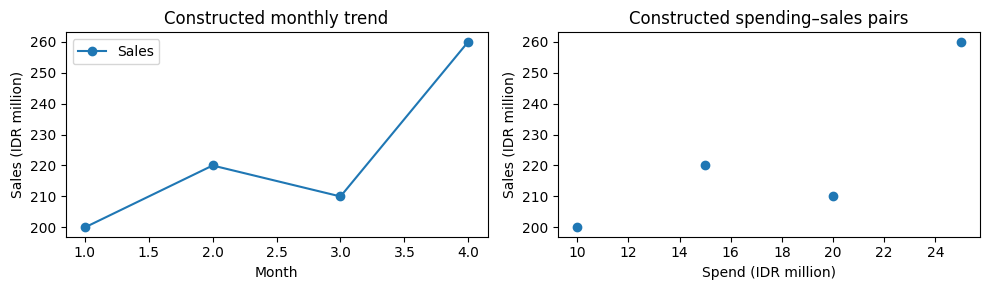

In [21]:
months = [1, 2, 3, 4]
example_sales = [200, 220, 210, 260]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(months, example_sales, marker="o", label="Sales")
axes[0].set(title="Constructed monthly trend", xlabel="Month", ylabel="Sales (IDR million)")
axes[0].legend()
axes[1].scatter([10, 15, 20, 25], example_sales)
axes[1].set(title="Constructed spending–sales pairs", xlabel="Spend (IDR million)", ylabel="Sales (IDR million)")
fig.tight_layout()
plt.show()

**Interpretation:** The line emphasizes time order; the scatter emphasizes a relationship between two measurements. The figures illustrate syntax, not observed client trends.

**Things to Remember:** Always label units. Use fig.tight_layout() to reduce overlapping labels. Legends explain multiple series.

### Technique: Histogram, bar chart, boxplot, subplots, and saving figures

**What is it?** These charts describe distributions and category summaries.

**Why do we use it?** A dashboard can present several complementary views together.

**When should we use it?** Use a histogram for frequencies, a bar for group comparisons, and a boxplot for median and spread.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

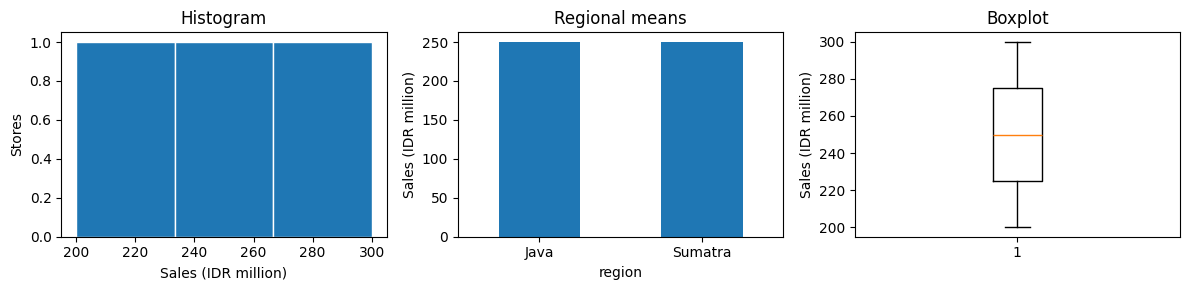

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(demo["sales"].dropna(), bins=3, edgecolor="white")
axes[0].set(title="Histogram", xlabel="Sales (IDR million)", ylabel="Stores")
demo.groupby("region")["sales"].mean().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Regional means", ylabel="Sales (IDR million)")
axes[2].boxplot(demo["sales"].dropna())
axes[2].set(title="Boxplot", ylabel="Sales (IDR million)")
fig.tight_layout()
fig.savefig("data/processed/syntax_demo_charts.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The bar compares regional means. The box spans the middle half of values and marks the median. The PNG can be reused in a report.

**Things to Remember:** Three observed sales values are too few for strong distribution claims. Boxplot points beyond whiskers are candidates for inspection, not automatically errors. Save before closing the figure.

## E. Summary and Quick Syntax Reference

Use named variables, check types and units, and choose operations that answer the question. Reference cells depend on earlier setup; copy the imports and required input definitions when adapting them.

| Goal | Reusable syntax |
|---|---|
| Create an array | `np.array([1, 2, 3])` |
| One-column matrix | `array.reshape(-1, 1)` |
| Missing-aware mean | `np.nanmean(array)` |
| Conditional values | `np.where(condition, yes, no)` |
| Unique values | `np.unique(array)` |
| Stack arrays | `np.concatenate([a, b])` |
| Read / export | `pd.read_csv(path)` / `df.to_csv(path, index=False)` |
| Inspect | `df.head()`, `df.shape`, `df.dtypes` |
| Choose columns | `df[["region", "sales"]]` |
| Labels / positions | `df.loc[mask, columns]` / `df.iloc[:5, :2]` |
| Filter | `df.loc[(df["sales"] > 250) & (df["region"] == "Java")]` |
| Sort | `df.sort_values("sales", ascending=False)` |
| Count missing | `df.isna().sum()` |
| Count categories | `df["region"].value_counts(dropna=False)` |
| Group summary | `df.groupby("region")["sales"].mean()` |
| Aggregate | `df.groupby("region").agg(avg=("sales", "mean"))` |
| Join / stack | `left.merge(right, on="key")` / `pd.concat([a, b])` |
| Pivot | `df.pivot_table(index="region", values="sales", aggfunc="mean")` |
| Chart and save | `fig, ax = plt.subplots()`; `fig.savefig(path)` |

## Practice exercises
1. From `client_data`, select Java stores spending more than IDR 20 million. Sort them by monthly sales, descending. **Check:** every returned row must satisfy both conditions.
2. Create a NumPy array `[5, np.nan, 15, 25]`. Compare `np.mean` and `np.nanmean`. **Check:** the missing-aware mean is 15.
3. Build a bar chart of the real dataset's store counts by region, label both axes, and save it in `data/processed/`. **Check:** bar heights sum to the dataset's row count.

**Common mistakes to avoid:** overwriting raw files, forgetting parentheses around Pandas conditions, confusing labels and positions, assuming NaN means zero, and making unlabeled charts.